In [1]:
!pip install -q "gymnasium[classic-control]" torch matplotlib

In [2]:
import os
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def make_env(env_id, seed):
    env = gym.make(env_id)
    env.reset(seed=seed)
    return env


def make_vec_env(env_id, n_envs, seed):
    envs = gym.vector.SyncVectorEnv([lambda: gym.make(env_id) for _ in range(n_envs)])
    envs.reset(seed=[seed + i for i in range(n_envs)])
    return envs


def mlp(sizes, activation=nn.ReLU, output_activation=nn.Identity):
    layers = []
    for i in range(len(sizes) - 1):
        act = activation if i < len(sizes) - 2 else output_activation
        layers += [nn.Linear(sizes[i], sizes[i + 1]), act()]
    return nn.Sequential(*layers)


def evaluate_policy(env_id, act_fn, episodes=20, seed=1000):
    env = gym.make(env_id)
    returns = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed + ep)
        done = False
        total = 0.0
        while not done:
            action = act_fn(obs)
            obs, reward, terminated, truncated, _ = env.step(action)
            total += reward
            done = terminated or truncated
        returns.append(total)
    env.close()
    return float(np.mean(returns))


def save_result(name, result):
    with open(os.path.join(RESULTS_DIR, f"{name}.json"), "w") as f:
        json.dump(result, f)


def load_result(name):
    with open(os.path.join(RESULTS_DIR, f"{name}.json")) as f:
        return json.load(f)

In [4]:
class QNetwork(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.net = mlp([obs_dim, 128, 128, act_dim])

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.capacity = capacity
        self.obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        self.dones = np.zeros(capacity, dtype=np.float32)
        self.ptr = 0
        self.size = 0

    def add(self, o, a, r, no, d):
        self.obs[self.ptr] = o
        self.actions[self.ptr] = a
        self.rewards[self.ptr] = r
        self.next_obs[self.ptr] = no
        self.dones[self.ptr] = d
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def sample(self, batch_size):
        idx = np.random.randint(0, self.size, size=batch_size)
        return (
            torch.as_tensor(self.obs[idx]),
            torch.as_tensor(self.actions[idx]),
            torch.as_tensor(self.rewards[idx]),
            torch.as_tensor(self.next_obs[idx]),
            torch.as_tensor(self.dones[idx]),
        )

In [5]:
def train_dqn(
    use_target_network=True,
    total_steps=200_000,
    eval_every=20_000,
    seed=0,
    lr=1e-3,
    buffer_size=50_000,
    batch_size=64,
    start_after=1_000,
    target_update_freq=500,
    eps_start=1.0,
    eps_end=0.05,
    eps_decay_steps=50_000,
    gamma=0.99,
    env_id="CartPole-v1",
):
    set_seed(seed)
    env = make_env(env_id, seed)
    obs_dim = env.observation_space.shape[0]
    act_dim = env.action_space.n

    q_net = QNetwork(obs_dim, act_dim).to(device)
    target_net = QNetwork(obs_dim, act_dim).to(device)
    target_net.load_state_dict(q_net.state_dict())
    optimizer = torch.optim.Adam(q_net.parameters(), lr=lr)
    buffer = ReplayBuffer(buffer_size, obs_dim)

    obs, _ = env.reset(seed=seed)
    episode_reward = 0.0
    train_rewards = []
    eval_steps, eval_rewards = [], []

    for step in range(1, total_steps + 1):
        eps = max(eps_end, eps_start - (eps_start - eps_end) * step / eps_decay_steps)
        if random.random() < eps:
            action = env.action_space.sample()
        else:
            with torch.no_grad():
                q_values = q_net(torch.as_tensor(obs, dtype=torch.float32, device=device))
            action = int(torch.argmax(q_values).item())

        next_obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        buffer.add(obs, action, reward, next_obs, float(terminated))
        episode_reward += reward
        obs = next_obs

        if done:
            train_rewards.append(episode_reward)
            episode_reward = 0.0
            obs, _ = env.reset()

        if buffer.size >= start_after:
            b_obs, b_actions, b_rewards, b_next_obs, b_dones = buffer.sample(batch_size)
            b_obs, b_next_obs = b_obs.to(device), b_next_obs.to(device)
            b_actions = b_actions.to(device)
            b_rewards, b_dones = b_rewards.to(device), b_dones.to(device)

            q_values = q_net(b_obs).gather(1, b_actions.unsqueeze(1)).squeeze(1)
            with torch.no_grad():
                target_source = target_net if use_target_network else q_net
                next_q = target_source(b_next_obs).max(1)[0]
                target = b_rewards + gamma * (1.0 - b_dones) * next_q

            loss = F.mse_loss(q_values, target)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            if use_target_network and step % target_update_freq == 0:
                target_net.load_state_dict(q_net.state_dict())

        if step % eval_every == 0:
            def act_fn(o, net=q_net):
                with torch.no_grad():
                    qv = net(torch.as_tensor(o, dtype=torch.float32, device=device))
                return int(torch.argmax(qv).item())

            avg_return = evaluate_policy(env_id, act_fn, episodes=20, seed=1000 + step)
            eval_steps.append(step)
            eval_rewards.append(avg_return)

    env.close()
    return {"train_rewards": train_rewards, "eval_steps": eval_steps, "eval_rewards": eval_rewards}

In [6]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.shared = mlp([obs_dim, 128, 128], output_activation=nn.ReLU)
        self.actor = nn.Linear(128, act_dim)
        self.critic = nn.Linear(128, 1)

    def forward(self, x):
        h = self.shared(x)
        return self.actor(h), self.critic(h).squeeze(-1)

In [7]:
def train_a2c(
    entropy_coef=0.01,
    total_steps=200_000,
    eval_every=20_000,
    seed=0,
    lr=7e-4,
    rollout_len=5,
    n_envs=4,
    value_coef=0.5,
    max_grad_norm=0.5,
    gamma=0.99,
    env_id="CartPole-v1",
):
    set_seed(seed)
    envs = make_vec_env(env_id, n_envs, seed)
    obs_dim = envs.single_observation_space.shape[0]
    act_dim = envs.single_action_space.n

    net = ActorCritic(obs_dim, act_dim).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    obs, _ = envs.reset(seed=seed)
    episode_rewards = np.zeros(n_envs)
    train_rewards = []
    eval_steps, eval_rewards = [], []

    updates = total_steps // (rollout_len * n_envs)
    global_step = 0

    for update in range(updates):
        obs_buf, act_buf, logp_buf, rew_buf, done_buf, val_buf, ent_buf = [], [], [], [], [], [], []

        for t in range(rollout_len):
            obs_t = torch.as_tensor(obs, dtype=torch.float32, device=device)
            logits, values = net(obs_t)
            dist = torch.distributions.Categorical(logits=logits)
            actions = dist.sample()

            next_obs, rewards, terminated, truncated, _ = envs.step(actions.cpu().numpy())
            dones = np.logical_or(terminated, truncated)

            obs_buf.append(obs_t)
            act_buf.append(actions)
            logp_buf.append(dist.log_prob(actions))
            ent_buf.append(dist.entropy())
            rew_buf.append(torch.as_tensor(rewards, dtype=torch.float32, device=device))
            done_buf.append(torch.as_tensor(dones, dtype=torch.float32, device=device))
            val_buf.append(values)

            episode_rewards += rewards
            for i, d in enumerate(dones):
                if d:
                    train_rewards.append(episode_rewards[i])
                    episode_rewards[i] = 0.0

            obs = next_obs
            global_step += n_envs

        with torch.no_grad():
            _, next_value = net(torch.as_tensor(obs, dtype=torch.float32, device=device))

        returns = torch.zeros(rollout_len, n_envs, device=device)
        R = next_value
        for t in reversed(range(rollout_len)):
            R = rew_buf[t] + gamma * (1.0 - done_buf[t]) * R
            returns[t] = R

        values_t = torch.stack(val_buf)
        logp_t = torch.stack(logp_buf)
        entropy = torch.stack(ent_buf).mean()
        advantages = (returns - values_t).detach()

        policy_loss = -(logp_t * advantages).mean()
        value_loss = F.mse_loss(values_t, returns)
        loss = policy_loss + value_coef * value_loss - entropy_coef * entropy

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(net.parameters(), max_grad_norm)
        optimizer.step()

        if global_step % eval_every < rollout_len * n_envs:
            def act_fn(o, net=net):
                with torch.no_grad():
                    logits, _ = net(torch.as_tensor(o, dtype=torch.float32, device=device))
                return int(torch.argmax(logits).item())

            avg_return = evaluate_policy(env_id, act_fn, episodes=20, seed=1000 + global_step)
            eval_steps.append(global_step)
            eval_rewards.append(avg_return)

    envs.close()
    return {"train_rewards": train_rewards, "eval_steps": eval_steps, "eval_rewards": eval_rewards}

In [8]:
def train_ppo(
    clip_range=0.2,
    total_steps=200_000,
    eval_every=20_000,
    seed=0,
    lr=3e-4,
    rollout_len=128,
    n_envs=4,
    gae_lambda=0.95,
    gamma=0.99,
    update_epochs=4,
    minibatch_size=128,
    entropy_coef=0.01,
    value_coef=0.5,
    max_grad_norm=0.5,
    env_id="CartPole-v1",
):
    set_seed(seed)
    envs = make_vec_env(env_id, n_envs, seed)
    obs_dim = envs.single_observation_space.shape[0]
    act_dim = envs.single_action_space.n

    net = ActorCritic(obs_dim, act_dim).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    obs, _ = envs.reset(seed=seed)
    episode_rewards = np.zeros(n_envs)
    train_rewards = []
    eval_steps, eval_rewards = [], []

    updates = total_steps // (rollout_len * n_envs)
    global_step = 0

    for update in range(updates):
        obs_buf = np.zeros((rollout_len, n_envs, obs_dim), dtype=np.float32)
        act_buf = np.zeros((rollout_len, n_envs), dtype=np.int64)
        logp_buf = np.zeros((rollout_len, n_envs), dtype=np.float32)
        rew_buf = np.zeros((rollout_len, n_envs), dtype=np.float32)
        done_buf = np.zeros((rollout_len, n_envs), dtype=np.float32)
        val_buf = np.zeros((rollout_len, n_envs), dtype=np.float32)

        for t in range(rollout_len):
            obs_t = torch.as_tensor(obs, dtype=torch.float32, device=device)
            with torch.no_grad():
                logits, values = net(obs_t)
                dist = torch.distributions.Categorical(logits=logits)
                actions = dist.sample()
                logp = dist.log_prob(actions)

            next_obs, rewards, terminated, truncated, _ = envs.step(actions.cpu().numpy())
            dones = np.logical_or(terminated, truncated)

            obs_buf[t] = obs
            act_buf[t] = actions.cpu().numpy()
            logp_buf[t] = logp.cpu().numpy()
            rew_buf[t] = rewards
            done_buf[t] = dones.astype(np.float32)
            val_buf[t] = values.cpu().numpy()

            episode_rewards += rewards
            for i, d in enumerate(dones):
                if d:
                    train_rewards.append(episode_rewards[i])
                    episode_rewards[i] = 0.0

            obs = next_obs
            global_step += n_envs

        with torch.no_grad():
            _, next_value = net(torch.as_tensor(obs, dtype=torch.float32, device=device))
            next_value = next_value.cpu().numpy()

        advantages = np.zeros((rollout_len, n_envs), dtype=np.float32)
        last_gae = np.zeros(n_envs, dtype=np.float32)
        for t in reversed(range(rollout_len)):
            next_v = next_value if t == rollout_len - 1 else val_buf[t + 1]
            next_nonterminal = 1.0 - done_buf[t]
            delta = rew_buf[t] + gamma * next_v * next_nonterminal - val_buf[t]
            last_gae = delta + gamma * gae_lambda * next_nonterminal * last_gae
            advantages[t] = last_gae
        returns = advantages + val_buf

        b_obs = torch.as_tensor(obs_buf.reshape(-1, obs_dim), device=device)
        b_act = torch.as_tensor(act_buf.reshape(-1), device=device)
        b_logp = torch.as_tensor(logp_buf.reshape(-1), device=device)
        b_adv = torch.as_tensor(advantages.reshape(-1), device=device)
        b_ret = torch.as_tensor(returns.reshape(-1), device=device)

        batch_size = rollout_len * n_envs
        indices = np.arange(batch_size)

        for epoch in range(update_epochs):
            np.random.shuffle(indices)
            for start in range(0, batch_size, minibatch_size):
                mb_idx = indices[start:start + minibatch_size]
                mb_obs = b_obs[mb_idx]
                mb_act = b_act[mb_idx]
                mb_old_logp = b_logp[mb_idx]
                mb_ret = b_ret[mb_idx]
                mb_adv = b_adv[mb_idx]
                mb_adv = (mb_adv - mb_adv.mean()) / (mb_adv.std() + 1e-8)

                logits, values = net(mb_obs)
                dist = torch.distributions.Categorical(logits=logits)
                new_logp = dist.log_prob(mb_act)
                entropy = dist.entropy().mean()

                ratio = torch.exp(new_logp - mb_old_logp)
                surr1 = ratio * mb_adv
                surr2 = torch.clamp(ratio, 1 - clip_range, 1 + clip_range) * mb_adv
                policy_loss = -torch.min(surr1, surr2).mean()
                value_loss = F.mse_loss(values, mb_ret)
                loss = policy_loss + value_coef * value_loss - entropy_coef * entropy

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(net.parameters(), max_grad_norm)
                optimizer.step()

        if global_step % eval_every < rollout_len * n_envs:
            def act_fn(o, net=net):
                with torch.no_grad():
                    logits, _ = net(torch.as_tensor(o, dtype=torch.float32, device=device))
                return int(torch.argmax(logits).item())

            avg_return = evaluate_policy(env_id, act_fn, episodes=20, seed=1000 + global_step)
            eval_steps.append(global_step)
            eval_rewards.append(avg_return)

    envs.close()
    return {"train_rewards": train_rewards, "eval_steps": eval_steps, "eval_rewards": eval_rewards}

In [9]:
EXPERIMENTS = {
    "dqn_target": lambda: train_dqn(use_target_network=True),
    "dqn_no_target": lambda: train_dqn(use_target_network=False),
    "a2c_entropy01": lambda: train_a2c(entropy_coef=0.01),
    "a2c_entropy0": lambda: train_a2c(entropy_coef=0.0),
    "ppo_clip02": lambda: train_ppo(clip_range=0.2),
    "ppo_clip01": lambda: train_ppo(clip_range=0.1),
    "ppo_clip03": lambda: train_ppo(clip_range=0.3),
}

results = {}
for name, run_fn in EXPERIMENTS.items():
    print(f"running {name}")
    result = run_fn()
    save_result(name, result)
    results[name] = result

running dqn_target
running dqn_no_target
running a2c_entropy01
running a2c_entropy0
running ppo_clip02
running ppo_clip01
running ppo_clip03


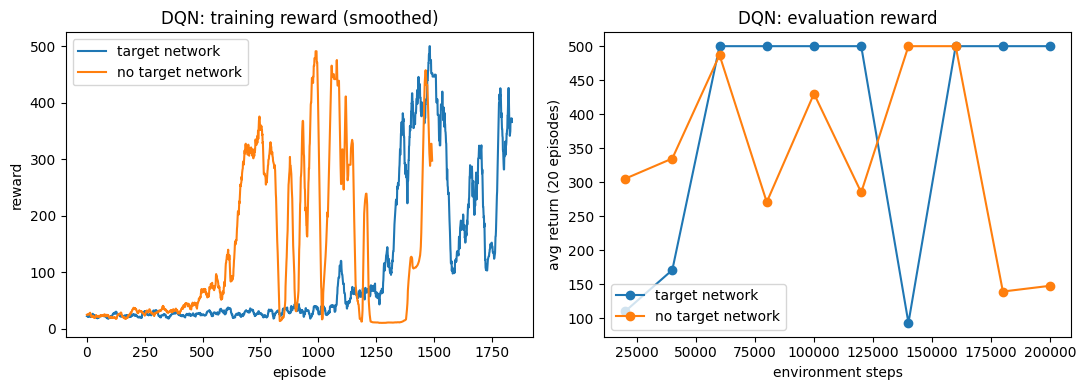

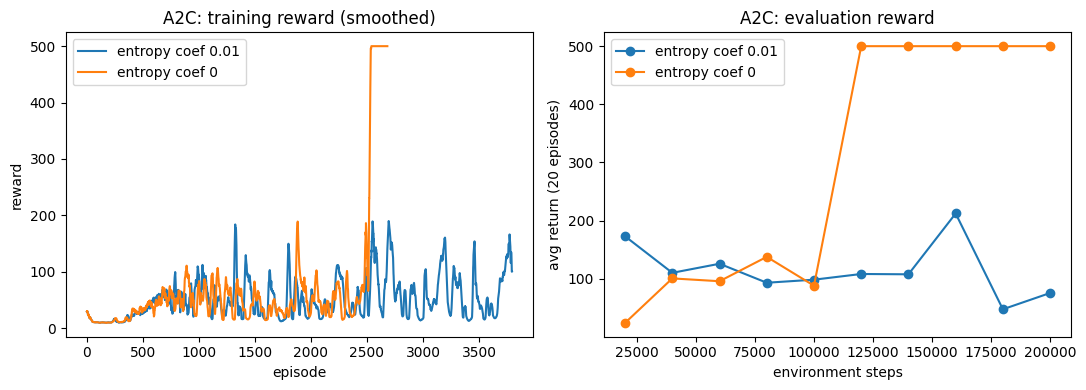

In [10]:
def smooth(values, window=20):
    if len(values) < window:
        return values
    kernel = np.ones(window) / window
    return np.convolve(values, kernel, mode="valid")


def plot_pair(name_a, label_a, name_b, label_b, title, filename):
    ra, rb = results[name_a], results[name_b]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    axes[0].plot(smooth(ra["train_rewards"]), label=label_a)
    axes[0].plot(smooth(rb["train_rewards"]), label=label_b)
    axes[0].set_title(f"{title}: training reward (smoothed)")
    axes[0].set_xlabel("episode")
    axes[0].set_ylabel("reward")
    axes[0].legend()

    axes[1].plot(ra["eval_steps"], ra["eval_rewards"], marker="o", label=label_a)
    axes[1].plot(rb["eval_steps"], rb["eval_rewards"], marker="o", label=label_b)
    axes[1].set_title(f"{title}: evaluation reward")
    axes[1].set_xlabel("environment steps")
    axes[1].set_ylabel("avg return (20 episodes)")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=150)
    plt.show()


plot_pair("dqn_target", "target network", "dqn_no_target", "no target network", "DQN", "dqn_comparison.png")
plot_pair("a2c_entropy01", "entropy coef 0.01", "a2c_entropy0", "entropy coef 0", "A2C", "a2c_comparison.png")

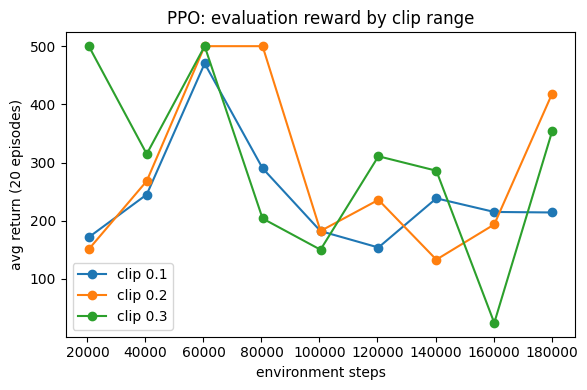

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, label in [("ppo_clip01", "clip 0.1"), ("ppo_clip02", "clip 0.2"), ("ppo_clip03", "clip 0.3")]:
    r = results[name]
    ax.plot(r["eval_steps"], r["eval_rewards"], marker="o", label=label)
ax.set_title("PPO: evaluation reward by clip range")
ax.set_xlabel("environment steps")
ax.set_ylabel("avg return (20 episodes)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "ppo_clip_comparison.png"), dpi=150)
plt.show()

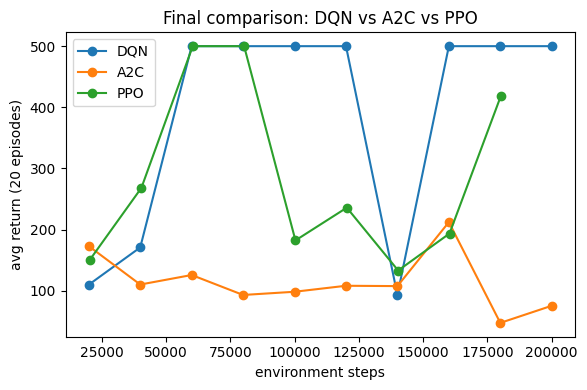

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, label in [("dqn_target", "DQN"), ("a2c_entropy01", "A2C"), ("ppo_clip02", "PPO")]:
    r = results[name]
    ax.plot(r["eval_steps"], r["eval_rewards"], marker="o", label=label)
ax.set_title("Final comparison: DQN vs A2C vs PPO")
ax.set_xlabel("environment steps")
ax.set_ylabel("avg return (20 episodes)")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "final_comparison.png"), dpi=150)
plt.show()

In [13]:
summary_rows = []
for name in ["dqn_target", "dqn_no_target", "a2c_entropy01", "a2c_entropy0",
             "ppo_clip01", "ppo_clip02", "ppo_clip03"]:
    final_eval = results[name]["eval_rewards"][-1] if results[name]["eval_rewards"] else float("nan")
    summary_rows.append((name, round(final_eval, 2)))

print(f"{'run':<18}{'final eval reward':>20}")
for name, val in summary_rows:
    print(f"{name:<18}{val:>20}")

run                  final eval reward
dqn_target                       500.0
dqn_no_target                   147.65
a2c_entropy01                     75.5
a2c_entropy0                     500.0
ppo_clip01                       214.2
ppo_clip02                      418.65
ppo_clip03                       354.0
